In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    classification_report,
    ConfusionMatrixDisplay,
    f1_score,
    accuracy_score
)

# Locate project root
root = (
    Path.cwd()
    if (Path.cwd() / "data").exists()
    else Path.cwd().parent
)

# Load data and remove duplicate rows
df = (
    pd.read_csv(root / "data" / "reviews.csv")
    .drop_duplicates()
    .reset_index(drop=True)
)

print("Initial dataset shape:", df.shape)
print("Columns:", df.columns.tolist())

# Validate required columns
required = {"text_", "rating"}
if not required.issubset(df.columns):
    raise ValueError(
        f"Missing required columns: {required - set(df.columns)}"
    )

# Prepare text and ratings
df["rating"] = pd.to_numeric(df["rating"], errors="coerce")
df["text_"] = df["text_"].fillna("").astype(str).str.strip()

df = df.dropna(subset=["rating"])
df = df[df["rating"].between(1, 5)]
df = df[df["text_"].ne("")].copy()

# Convert ratings into sentiment labels
def to_sentiment(rating):
    if rating >= 4:
        return "positive"
    elif rating == 3:
        return "neutral"
    else:
        return "negative"

df["sentiment"] = df["rating"].apply(to_sentiment)

X = df["text_"]
y = df["sentiment"]

# Stratified train/test split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nUsable reviews:", len(df))
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nSentiment counts:")
print(y.value_counts())

print("\nSentiment proportions:")
print(y.value_counts(normalize=True).round(3))

print("\nTraining sentiment counts:")
print(y_train.value_counts())


Initial dataset shape: (40420, 4)
Columns: ['category', 'rating', 'label', 'text_']

Usable reviews: 40420
Training samples: 32336
Testing samples: 8084

Sentiment counts:
sentiment
positive    32512
negative     4122
neutral      3786
Name: count, dtype: int64

Sentiment proportions:
sentiment
positive    0.804
negative    0.102
neutral     0.094
Name: proportion, dtype: float64

Training sentiment counts:
sentiment
positive    26010
negative     3297
neutral      3029
Name: count, dtype: int64


In [3]:

def make_model(class_weight=None):
    return Pipeline([
        (
            "tfidf",
            TfidfVectorizer(
                lowercase=True,
                max_features=50000,
                ngram_range=(1, 2)
            )
        ),
        (
            "clf",
            LogisticRegression(
                max_iter=1000,
                class_weight=class_weight,
                random_state=42
            )
        )
    ])


results = {}

for name, weights in [
    ("No class weights", None),
    ("class_weight=balanced", "balanced")
]:
    model = make_model(weights)
    model.fit(X_train, y_train)

    predictions = model.predict(X_test)
    results[name] = (model, predictions)

    print(f"\n{'=' * 18} {name} {'=' * 18}")

    print(
        "Accuracy:",
        round(accuracy_score(y_test, predictions), 4)
    )

    print(
        "Macro F1:",
        round(f1_score(
            y_test,
            predictions,
            average="macro"
        ), 4)
    )

    print(
        classification_report(
            y_test,
            predictions,
            labels=["negative", "neutral", "positive"],
            digits=3,
            zero_division=0
        )
    )
    
# Train the class-weighted model
model_balanced = make_model(class_weight="balanced")
model_balanced.fit(X_train, y_train)

pred_balanced = model_balanced.predict(X_test)

print("Accuracy:", round(
    accuracy_score(y_test, pred_balanced), 4
))
print("Macro F1:", round(
    f1_score(y_test, pred_balanced, average="macro"), 4
))

print("\nClassification Report:")
print(classification_report(
    y_test,
    pred_balanced,
    labels=["negative", "neutral", "positive"],
    digits=3,
    zero_division=0
))

# Store results for the next cells
results["class_weight=balanced"] = (
    model_balanced,
    pred_balanced
)




================== No class weights ==================
Accuracy: 0.8193
Macro F1: 0.4254
              precision    recall  f1-score   support

    negative      0.750     0.189     0.302       825
     neutral      0.365     0.041     0.074       757
    positive      0.826     0.990     0.901      6502

    accuracy                          0.819      8084
   macro avg      0.647     0.407     0.425      8084
weighted avg      0.775     0.819     0.762      8084


================== class_weight=balanced ==================
Accuracy: 0.7067
Macro F1: 0.5059
              precision    recall  f1-score   support

    negative      0.359     0.492     0.415       825
     neutral      0.208     0.386     0.271       757
    positive      0.903     0.771     0.832      6502

    accuracy                          0.707      8084
   macro avg      0.490     0.550     0.506      8084
weighted avg      0.783     0.707     0.737      8084



In [5]:

# Generate predictions using the balanced model

model_balanced = make_model(class_weight="balanced")
model_balanced.fit(X_train, y_train)

pred_balanced = model_balanced.predict(X_test)

print("Balanced model predictions created:", len(pred_balanced))


Balanced model predictions created: 8084


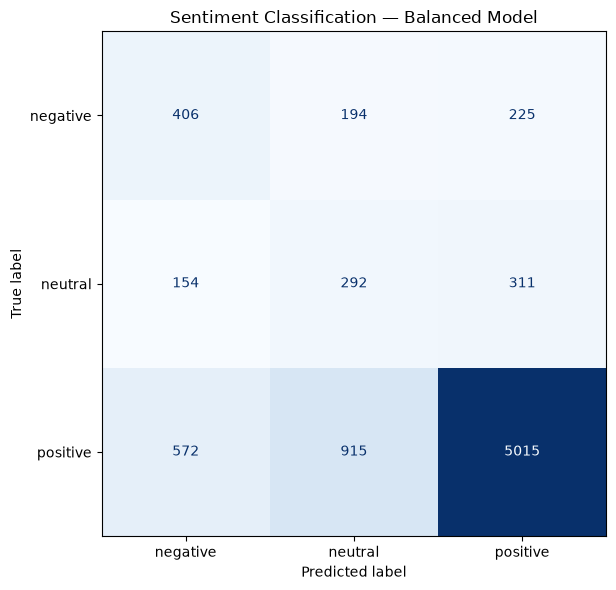

In [6]:

import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

# Use the balanced model's predictions
labels = ["negative", "neutral", "positive"]

cm = confusion_matrix(
    y_test,
    pred_balanced,
    labels=labels
)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=labels
)

fig, ax = plt.subplots(figsize=(7, 6))
display.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=False
)

ax.set_title("Sentiment Classification — Balanced Model")
plt.tight_layout()
plt.show()


In [7]:

# Test the sentiment model with example reviews

sample_reviews = [
    "This product is excellent and works perfectly. I love it!",
    "Terrible quality. It stopped working after one day.",
    "The product is okay, nothing special.",
    "Amazing quality and fast delivery. Highly recommended!",
    "Very disappointing. The product is damaged and useless.",
    "The product arrived today and looks as expected."
]

predictions = model_balanced.predict(sample_reviews)

for review, sentiment in zip(sample_reviews, predictions):
    print("Review:", review)
    print("Predicted sentiment:", sentiment.upper())
    print("-" * 70)


Review: This product is excellent and works perfectly. I love it!
Predicted sentiment: POSITIVE
----------------------------------------------------------------------
Review: Terrible quality. It stopped working after one day.
Predicted sentiment: NEGATIVE
----------------------------------------------------------------------
Review: The product is okay, nothing special.
Predicted sentiment: NEUTRAL
----------------------------------------------------------------------
Review: Amazing quality and fast delivery. Highly recommended!
Predicted sentiment: POSITIVE
----------------------------------------------------------------------
Review: Very disappointing. The product is damaged and useless.
Predicted sentiment: NEGATIVE
----------------------------------------------------------------------
Review: The product arrived today and looks as expected.
Predicted sentiment: POSITIVE
----------------------------------------------------------------------


In [8]:

from pathlib import Path
import joblib

# Find the project root
root = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent

# Create an output folder if it does not exist
output_dir = root / "outputs"
output_dir.mkdir(parents=True, exist_ok=True)

# Save the balanced sentiment model
model_path = output_dir / "sentiment_model.joblib"
joblib.dump(model_balanced, model_path)

print("Model saved to:", model_path)


Model saved to: c:\Users\poona\OneDrive\Desktop\parkh\outputs\sentiment_model.joblib


In [9]:

import pandas as pd
from sklearn.metrics import accuracy_score, f1_score

evaluation_rows = []

for name, (model, predictions) in results.items():
    evaluation_rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Macro F1": f1_score(
            y_test,
            predictions,
            average="macro",
            zero_division=0
        )
    })

evaluation_df = pd.DataFrame(evaluation_rows)

csv_path = output_dir / "sentiment_model_comparison.csv"
evaluation_df.to_csv(csv_path, index=False)

print(evaluation_df.round(4).to_string(index=False))
print("\nResults saved to:", csv_path)


                Model  Accuracy  Macro F1
     No class weights    0.8193    0.4254
class_weight=balanced    0.7067    0.5059

Results saved to: c:\Users\poona\OneDrive\Desktop\parkh\outputs\sentiment_model_comparison.csv


In [10]:

print("Model exists:", model_path.exists())
print("Model size:", round(model_path.stat().st_size / 1024, 2), "KB")
print("CSV exists:", csv_path.exists())
print("CSV size:", round(csv_path.stat().st_size / 1024, 2), "KB")


Model exists: True
Model size: 3080.64 KB
CSV exists: True
CSV size: 0.14 KB
